In [113]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sb
import numpy as np

In [114]:
df = pd.read_csv('../datasets/Airbnb_Open_Data.csv',dtype={25: str})

In [115]:
df

,id,NAME,host id,host_identity_verified,host name,neighbourhood group,neighbourhood,lat,long,country,...,service fee,minimum nights,number of reviews,last review,reviews per month,review rate number,calculated host listings count,availability 365,house_rules,license
0,1001254,Clean & quiet apt home by the park,80014485718,unconfirmed,Madaline,Brooklyn,Kensington,40.64749,-73.97237,United States,...,$193,10.0,9.0,10/19/2021,0.21,4.0,6.0,286.0,Clean up and treat the home the way you'd like...,NaN
1,1002102,Skylit Midtown Castle,52335172823,verified,Jenna,Manhattan,Midtown,40.75362,-73.98377,United States,...,$28,30.0,45.0,5/21/2022,0.38,4.0,2.0,228.0,Pet friendly but please confirm with me if the...,NaN
2,1002403,THE VILLAGE OF HARLEM....NEW YORK !,78829239556,NaN,Elise,Manhattan,Harlem,40.80902,-73.94190,United States,...,$124,3.0,0.0,NaN,NaN,5.0,1.0,352.0,"I encourage you to use my kitchen, cooking and...",NaN
3,1002755,NaN,85098326012,unconfirmed,Garry,Brooklyn,Clinton Hill,40.68514,-73.95976,United States,...,$74,30.0,270.0,7/5/2019,4.64,4.0,1.0,322.0,NaN,NaN
4,1003689,Entire Apt: Spacious Studio/Loft by central park,92037596077,verified,Lyndon,Manhattan,East Harlem,40.79851,-73.94399,United States,...,$41,10.0,9.0,11/19/2018,0.10,3.0,1.0,289.0,"Please no smoking in the house, porch or on th...",NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
102594,6092437,Spare room in Williamsburg,12312296767,verified,Krik,Brooklyn,Williamsburg,40.70862,-73.94651,United States,...,$169,1.0,0.0,NaN,NaN,3.0,1.0,227.0,No Smoking No Parties or Events of any kind Pl...,NaN
102595,6092990,Best Location near Columbia U,77864383453,unconfirmed,Mifan,Manhattan,Morningside Heights,40.80460,-73.96545,United States,...,$167,1.0,1.0,7/6/2015,0.02,2.0,2.0,395.0,House rules: Guests agree to the following ter...,NaN
102596,6093542,"Comfy, bright room in Brooklyn",69050334417,unconfirmed,Megan,Brooklyn,Park Slope,40.67505,-73.98045,United States,...,$198,3.0,0.0,NaN,NaN,5.0,1.0,342.0,NaN,NaN
102597,6094094,Big Studio-One Stop from Midtown,11160591270,unconfirmed,Christopher,Queens,Long Island City,40.74989,-73.93777,United States,...,$109,2.0,5.0,10/11/2015,0.10,3.0,1.0,386.0,NaN,NaN


In [116]:
# Data preparation

In [117]:
df.isnull().sum()

id                                     0
NAME                                 250
host id                                0
host_identity_verified               289
host name                            406
neighbourhood group                   29
neighbourhood                         16
lat                                    8
long                                   8
country                              532
country code                         131
instant_bookable                     105
cancellation_policy                   76
room type                              0
Construction year                    214
price                                247
service fee                          273
minimum nights                       409
number of reviews                    183
last review                        15893
reviews per month                  15879
review rate number                   326
calculated host listings count       319
availability 365                     448
house_rules     

In [118]:
df.columns

Index(['id', 'NAME', 'host id', 'host_identity_verified', 'host name',
       'neighbourhood group', 'neighbourhood', 'lat', 'long', 'country',
       'country code', 'instant_bookable', 'cancellation_policy', 'room type',
       'Construction year', 'price', 'service fee', 'minimum nights',
       'number of reviews', 'last review', 'reviews per month',
       'review rate number', 'calculated host listings count',
       'availability 365', 'house_rules', 'license'],
      dtype='object')

In [119]:
df.dtypes

id                                  int64
NAME                               object
host id                             int64
host_identity_verified             object
host name                          object
neighbourhood group                object
neighbourhood                      object
lat                               float64
long                              float64
country                            object
country code                       object
instant_bookable                   object
cancellation_policy                object
room type                          object
Construction year                 float64
price                              object
service fee                        object
minimum nights                    float64
number of reviews                 float64
last review                        object
reviews per month                 float64
review rate number                float64
calculated host listings count    float64
availability 365                  

In [120]:
df = df.rename(columns={'NAME':'name','host id':'host_id','host name':'host_name','neighbourhood group':'neighbourhood_group','neighbourhood	':'neighbourhood',
                        'country code':'country_code','room type':'room_type','Construction year':'Construction_year','service fee':'service_fee','minimum nights':'minimum_nights',
                        'number of reviews':'number_of_reviews','last review':'last_review','reviews per month':'reviews_per_month','review rate number':'review_rate_number',
                        'calculated host listings count':'calculated_host_listings_count','availability 365':'availability'})

In [121]:
df = df.drop(['id','lat','long','country_code'],axis=1)

In [122]:
df

,name,host_id,host_identity_verified,host_name,neighbourhood_group,neighbourhood,country,instant_bookable,cancellation_policy,room_type,...,service_fee,minimum_nights,number_of_reviews,last_review,reviews_per_month,review_rate_number,calculated_host_listings_count,availability,house_rules,license
0,Clean & quiet apt home by the park,80014485718,unconfirmed,Madaline,Brooklyn,Kensington,United States,False,strict,Private room,...,$193,10.0,9.0,10/19/2021,0.21,4.0,6.0,286.0,Clean up and treat the home the way you'd like...,NaN
1,Skylit Midtown Castle,52335172823,verified,Jenna,Manhattan,Midtown,United States,False,moderate,Entire home/apt,...,$28,30.0,45.0,5/21/2022,0.38,4.0,2.0,228.0,Pet friendly but please confirm with me if the...,NaN
2,THE VILLAGE OF HARLEM....NEW YORK !,78829239556,NaN,Elise,Manhattan,Harlem,United States,True,flexible,Private room,...,$124,3.0,0.0,NaN,NaN,5.0,1.0,352.0,"I encourage you to use my kitchen, cooking and...",NaN
3,NaN,85098326012,unconfirmed,Garry,Brooklyn,Clinton Hill,United States,True,moderate,Entire home/apt,...,$74,30.0,270.0,7/5/2019,4.64,4.0,1.0,322.0,NaN,NaN
4,Entire Apt: Spacious Studio/Loft by central park,92037596077,verified,Lyndon,Manhattan,East Harlem,United States,False,moderate,Entire home/apt,...,$41,10.0,9.0,11/19/2018,0.10,3.0,1.0,289.0,"Please no smoking in the house, porch or on th...",NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
102594,Spare room in Williamsburg,12312296767,verified,Krik,Brooklyn,Williamsburg,United States,False,flexible,Private room,...,$169,1.0,0.0,NaN,NaN,3.0,1.0,227.0,No Smoking No Parties or Events of any kind Pl...,NaN
102595,Best Location near Columbia U,77864383453,unconfirmed,Mifan,Manhattan,Morningside Heights,United States,True,moderate,Private room,...,$167,1.0,1.0,7/6/2015,0.02,2.0,2.0,395.0,House rules: Guests agree to the following ter...,NaN
102596,"Comfy, bright room in Brooklyn",69050334417,unconfirmed,Megan,Brooklyn,Park Slope,United States,True,moderate,Private room,...,$198,3.0,0.0,NaN,NaN,5.0,1.0,342.0,NaN,NaN
102597,Big Studio-One Stop from Midtown,11160591270,unconfirmed,Christopher,Queens,Long Island City,United States,True,strict,Entire home/apt,...,$109,2.0,5.0,10/11/2015,0.10,3.0,1.0,386.0,NaN,NaN


In [123]:
df['price'] = pd.to_numeric(df['price'].replace(r'[$,]','',regex=True),errors='coerce')
df['service_fee'] = pd.to_numeric(df['service_fee'].replace(r'[$,]','', regex=True), errors='coerce')
df['last_review'] = pd.to_datetime(df['last_review'].replace, errors='coerce')

In [124]:
for col in df.columns:
    if df [col].dtype == 'object':
       df[col] = df[col] .fillna ('unkown' )
    else:
         df[col] = df[col].fillna(df[col].mean())

In [125]:
df.isnull().sum()

name                                   0
host_id                                0
host_identity_verified                 0
host_name                              0
neighbourhood_group                    0
neighbourhood                          0
country                                0
instant_bookable                       0
cancellation_policy                    0
room_type                              0
Construction_year                      0
price                                  0
service_fee                            0
minimum_nights                         0
number_of_reviews                      0
last_review                       102599
reviews_per_month                      0
review_rate_number                     0
calculated_host_listings_count         0
availability                           0
house_rules                            0
license                                0
dtype: int64

In [126]:
df

,name,host_id,host_identity_verified,host_name,neighbourhood_group,neighbourhood,country,instant_bookable,cancellation_policy,room_type,...,service_fee,minimum_nights,number_of_reviews,last_review,reviews_per_month,review_rate_number,calculated_host_listings_count,availability,house_rules,license
0,Clean & quiet apt home by the park,80014485718,unconfirmed,Madaline,Brooklyn,Kensington,United States,False,strict,Private room,...,193.0,10.0,9.0,NaT,0.210000,4.0,6.0,286.0,Clean up and treat the home the way you'd like...,unkown
1,Skylit Midtown Castle,52335172823,verified,Jenna,Manhattan,Midtown,United States,False,moderate,Entire home/apt,...,28.0,30.0,45.0,NaT,0.380000,4.0,2.0,228.0,Pet friendly but please confirm with me if the...,unkown
2,THE VILLAGE OF HARLEM....NEW YORK !,78829239556,unkown,Elise,Manhattan,Harlem,United States,True,flexible,Private room,...,124.0,3.0,0.0,NaT,1.374022,5.0,1.0,352.0,"I encourage you to use my kitchen, cooking and...",unkown
3,unkown,85098326012,unconfirmed,Garry,Brooklyn,Clinton Hill,United States,True,moderate,Entire home/apt,...,74.0,30.0,270.0,NaT,4.640000,4.0,1.0,322.0,unkown,unkown
4,Entire Apt: Spacious Studio/Loft by central park,92037596077,verified,Lyndon,Manhattan,East Harlem,United States,False,moderate,Entire home/apt,...,41.0,10.0,9.0,NaT,0.100000,3.0,1.0,289.0,"Please no smoking in the house, porch or on th...",unkown
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
102594,Spare room in Williamsburg,12312296767,verified,Krik,Brooklyn,Williamsburg,United States,False,flexible,Private room,...,169.0,1.0,0.0,NaT,1.374022,3.0,1.0,227.0,No Smoking No Parties or Events of any kind Pl...,unkown
102595,Best Location near Columbia U,77864383453,unconfirmed,Mifan,Manhattan,Morningside Heights,United States,True,moderate,Private room,...,167.0,1.0,1.0,NaT,0.020000,2.0,2.0,395.0,House rules: Guests agree to the following ter...,unkown
102596,"Comfy, bright room in Brooklyn",69050334417,unconfirmed,Megan,Brooklyn,Park Slope,United States,True,moderate,Private room,...,198.0,3.0,0.0,NaT,1.374022,5.0,1.0,342.0,unkown,unkown
102597,Big Studio-One Stop from Midtown,11160591270,unconfirmed,Christopher,Queens,Long Island City,United States,True,strict,Entire home/apt,...,109.0,2.0,5.0,NaT,0.100000,3.0,1.0,386.0,unkown,unkown


In [127]:
df.describe()

,host_id,Construction_year,price,service_fee,minimum_nights,number_of_reviews,last_review,reviews_per_month,review_rate_number,calculated_host_listings_count,availability
count,1.025990e+05,102599.000000,102599.000000,102599.000000,102599.000000,102599.000000,0,102599.000000,102599.000000,102599.000000,102599.000000
mean,4.925411e+10,2012.487464,625.293536,125.026924,8.135845,27.483743,NaT,1.374022,3.279106,7.936605,141.133254
min,1.236005e+08,2003.000000,50.000000,10.000000,-1223.000000,0.000000,NaT,0.010000,1.000000,1.000000,-10.000000
25%,2.458333e+10,2008.000000,341.000000,68.000000,2.000000,1.000000,NaT,0.280000,2.000000,1.000000,3.000000
50%,4.911774e+10,2012.000000,625.293536,125.000000,3.000000,7.000000,NaT,1.050000,3.000000,1.000000,98.000000
75%,7.399650e+10,2017.000000,912.000000,182.000000,5.000000,30.000000,NaT,1.710000,4.000000,2.000000,268.000000
max,9.876313e+10,2022.000000,1200.000000,240.000000,5645.000000,1024.000000,NaT,90.000000,5.000000,332.000000,3677.000000
std,2.853900e+10,5.759540,331.272131,66.237438,30.492820,49.464781,NaN,1.605782,1.282614,32.168654,135.139008


In [128]:
df.host_id.unique()

array([80014485718, 52335172823, 78829239556, ..., 23801060917,
       15593031571, 93578954226], shape=(102057,))

In [129]:
df.Construction_year.unique()

array([2020.        , 2007.        , 2005.        , 2009.        ,
       2013.        , 2015.        , 2004.        , 2008.        ,
       2010.        , 2019.        , 2018.        , 2006.        ,
       2016.        , 2017.        , 2021.        , 2003.        ,
       2011.        , 2012.        , 2022.        , 2014.        ,
       2012.48746398])

In [130]:
df.Construction_year = df.Construction_year.astype('int64')

In [131]:
df.price.unique()

array([ 966.,  142.,  620., ..., 1184.,  905.,  309.], shape=(1152,))

In [132]:
df.price = df.price.replace('[$,]','',regex=True).astype('int64')

In [133]:
df.dtypes

name                                      object
host_id                                    int64
host_identity_verified                    object
host_name                                 object
neighbourhood_group                       object
neighbourhood                             object
country                                   object
instant_bookable                          object
cancellation_policy                       object
room_type                                 object
Construction_year                          int64
price                                      int64
service_fee                              float64
minimum_nights                           float64
number_of_reviews                        float64
last_review                       datetime64[ns]
reviews_per_month                        float64
review_rate_number                       float64
calculated_host_listings_count           float64
availability                             float64
house_rules         

In [134]:
df

,name,host_id,host_identity_verified,host_name,neighbourhood_group,neighbourhood,country,instant_bookable,cancellation_policy,room_type,...,service_fee,minimum_nights,number_of_reviews,last_review,reviews_per_month,review_rate_number,calculated_host_listings_count,availability,house_rules,license
0,Clean & quiet apt home by the park,80014485718,unconfirmed,Madaline,Brooklyn,Kensington,United States,False,strict,Private room,...,193.0,10.0,9.0,NaT,0.210000,4.0,6.0,286.0,Clean up and treat the home the way you'd like...,unkown
1,Skylit Midtown Castle,52335172823,verified,Jenna,Manhattan,Midtown,United States,False,moderate,Entire home/apt,...,28.0,30.0,45.0,NaT,0.380000,4.0,2.0,228.0,Pet friendly but please confirm with me if the...,unkown
2,THE VILLAGE OF HARLEM....NEW YORK !,78829239556,unkown,Elise,Manhattan,Harlem,United States,True,flexible,Private room,...,124.0,3.0,0.0,NaT,1.374022,5.0,1.0,352.0,"I encourage you to use my kitchen, cooking and...",unkown
3,unkown,85098326012,unconfirmed,Garry,Brooklyn,Clinton Hill,United States,True,moderate,Entire home/apt,...,74.0,30.0,270.0,NaT,4.640000,4.0,1.0,322.0,unkown,unkown
4,Entire Apt: Spacious Studio/Loft by central park,92037596077,verified,Lyndon,Manhattan,East Harlem,United States,False,moderate,Entire home/apt,...,41.0,10.0,9.0,NaT,0.100000,3.0,1.0,289.0,"Please no smoking in the house, porch or on th...",unkown
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
102594,Spare room in Williamsburg,12312296767,verified,Krik,Brooklyn,Williamsburg,United States,False,flexible,Private room,...,169.0,1.0,0.0,NaT,1.374022,3.0,1.0,227.0,No Smoking No Parties or Events of any kind Pl...,unkown
102595,Best Location near Columbia U,77864383453,unconfirmed,Mifan,Manhattan,Morningside Heights,United States,True,moderate,Private room,...,167.0,1.0,1.0,NaT,0.020000,2.0,2.0,395.0,House rules: Guests agree to the following ter...,unkown
102596,"Comfy, bright room in Brooklyn",69050334417,unconfirmed,Megan,Brooklyn,Park Slope,United States,True,moderate,Private room,...,198.0,3.0,0.0,NaT,1.374022,5.0,1.0,342.0,unkown,unkown
102597,Big Studio-One Stop from Midtown,11160591270,unconfirmed,Christopher,Queens,Long Island City,United States,True,strict,Entire home/apt,...,109.0,2.0,5.0,NaT,0.100000,3.0,1.0,386.0,unkown,unkown


In [135]:
df.last_review.unique()

<DatetimeArray>
['NaT']
Length: 1, dtype: datetime64[ns]

In [136]:
df.price.mean()

np.float64(625.2928293648087)

In [137]:
df.minimum_nights.mean()

np.float64(8.13584499461787)

In [138]:
df.number_of_reviews.mean()

np.float64(27.483742774566473)

In [139]:
df.name = df.name.fillna('unknown')
df.host_identity_verified = df.host_identity_verified.fillna('unknown')
df.host_name = df.host_name.fillna('unknown')
df.neighbourhood_group = df.neighbourhood_group.fillna('unknown')
df.neighbourhood = df.neighbourhood.fillna('unknown')
df.country = df.country.fillna('unknown')
df.instant_bookable = df.instant_bookable.fillna('unknown')
df.cancellation_policy = df.cancellation_policy.fillna('unknown')
df.Construction_year = df.Construction_year.fillna(2012)
df.price = df.price.fillna(625)
df.service_fee = df.service_fee.fillna(125)
df.minimum_nights = df.minimum_nights.fillna(8.135)
df.number_of_reviews = df.number_of_reviews.fillna(27)
df.last_review = df.last_review.fillna(0)
df.reviews_per_month = df.reviews_per_month.fillna(1.37)
df.review_rate_number = df.review_rate_number.fillna(3.27)
df.calculated_host_listings_count = df.calculated_host_listings_count.fillna(7.93)
df.availability = df.availability.fillna(141)
df.license = df.license.fillna('unknown')

C:\Users\yawal\AppData\Local\Temp\ipykernel_14816\1359826024.py:14: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.last_review = df.last_review.fillna(0)


In [140]:
df.isnull().sum()

name                              0
host_id                           0
host_identity_verified            0
host_name                         0
neighbourhood_group               0
neighbourhood                     0
country                           0
instant_bookable                  0
cancellation_policy               0
room_type                         0
Construction_year                 0
price                             0
service_fee                       0
minimum_nights                    0
number_of_reviews                 0
last_review                       0
reviews_per_month                 0
review_rate_number                0
calculated_host_listings_count    0
availability                      0
house_rules                       0
license                           0
dtype: int64

In [141]:
#1. Location & Listings Analysis:

In [142]:
df.neighbourhood_group.value_counts().nlargest(10)

neighbourhood_group
Manhattan        43792
Brooklyn         41842
Queens           13267
Bronx             2712
Staten Island      955
unkown              29
brookln              1
manhatan             1
Name: count, dtype: int64

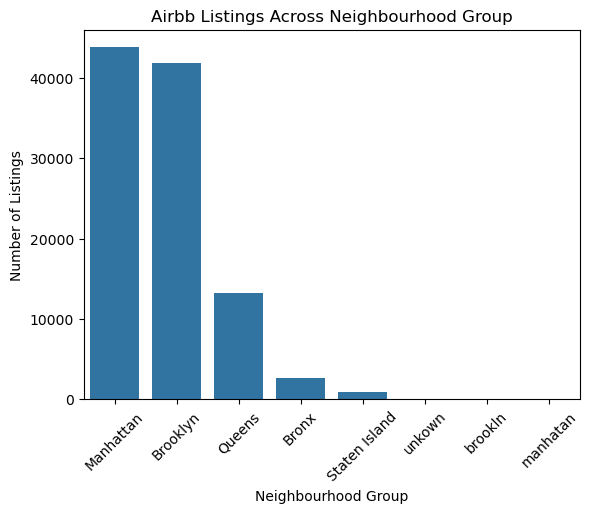

In [143]:
sb.countplot(data=df, x='neighbourhood_group',order=df['neighbourhood_group'].value_counts().index)
plt.title('Airbb Listings Across Neighbourhood Group') 
plt.xlabel('Neighbourhood Group')
plt.ylabel('Number of Listings') 
plt.xticks(rotation=45)
plt.show()

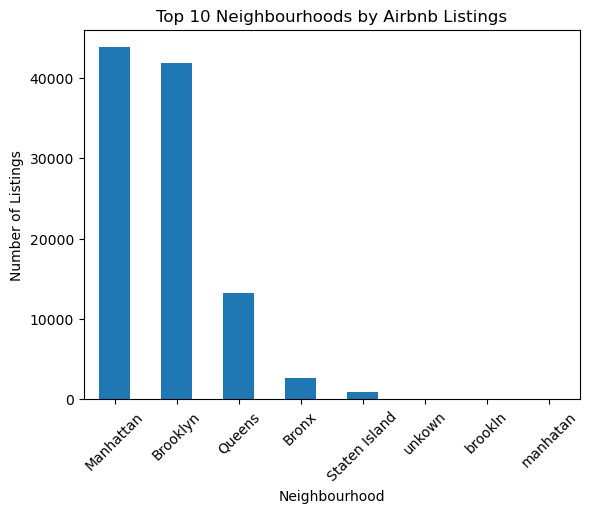

In [144]:
df.neighbourhood_group.value_counts().nlargest(10).plot(kind='bar')
plt. title('Top 10 Neighbourhoods by Airbnb Listings') 
plt.xlabel('Neighbourhood')
plt.ylabel('Number of Listings') 
plt.xticks(rotation=45)
plt.show()

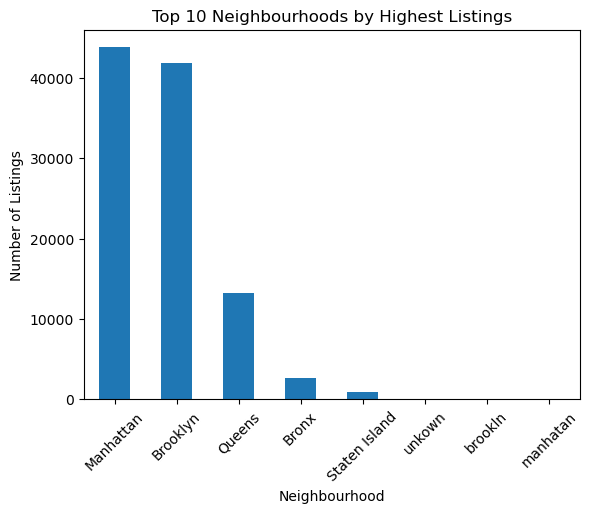

In [145]:
df.neighbourhood_group.value_counts().nlargest(10).plot(kind='bar')
plt. title('Top 10 Neighbourhoods by Highest Listings') 
plt.xlabel('Neighbourhood')
plt.ylabel('Number of Listings') 
plt.xticks(rotation=45)
plt.show()

In [146]:
df.groupby('neighbourhood_group')['room_type'].value_counts()

neighbourhood_group  room_type      
Bronx                Private room        1573
                     Entire home/apt     1022
                     Shared room          117
Brooklyn             Entire home/apt    20575
                     Private room       20434
                     Shared room          825
                     Hotel room             8
Manhattan            Entire home/apt    26473
                     Private room       16312
                     Shared room          907
                     Hotel room           100
Queens               Private room        7751
                     Entire home/apt     5146
                     Shared room          362
                     Hotel room             8
Staten Island        Entire home/apt      474
                     Private room         466
                     Shared room           15
brookln              Private room           1
manhatan             Private room           1
unkown               Private room          

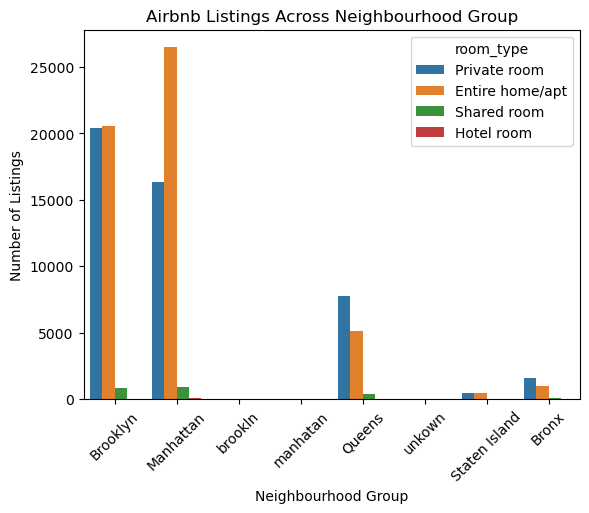

In [147]:
sb.countplot (data=df, x='neighbourhood_group', hue='room_type')
plt.title('Airbnb Listings Across Neighbourhood Group') 
plt.xlabel('Neighbourhood Group')
plt.ylabel('Number of Listings') 
plt.xticks(rotation=45)
plt.show()

In [148]:
#2. Pricing Analysis:

In [149]:
avg_price = df.groupby('neighbourhood')['price'].mean().nlargest(10)
avg_price

neighbourhood
New Dorp                  1045.000000
Chelsea, Staten Island    1042.000000
Fort Wadsworth            1024.000000
Little Neck                817.750000
Jamaica Hills              812.904762
Arden Heights              804.888889
Midland Beach              796.176471
Shore Acres                792.260870
Mill Basin                 775.142857
Riverdale                  768.736842
Name: price, dtype: float64

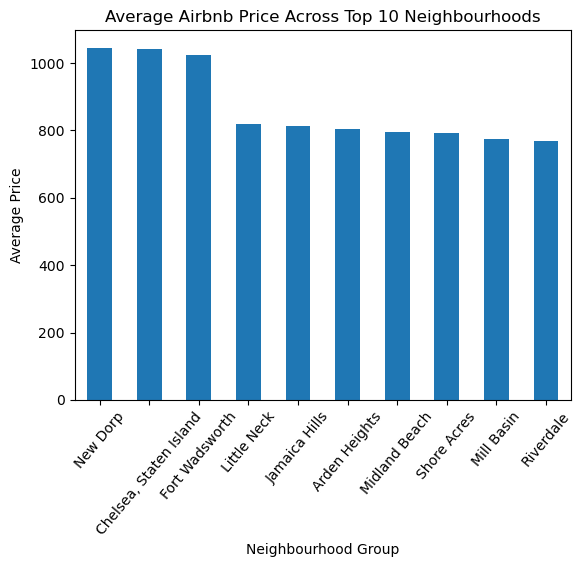

In [150]:
avg_price.plot (kind='bar')
plt.title('Average Airbnb Price Across Top 10 Neighbourhoods') 
plt.xlabel('Neighbourhood Group')
plt.ylabel('Average Price')
plt.xticks(rotation=50)
plt.show()

In [151]:
ng_avg = df.groupby('neighbourhood')[ 'price'].mean()
ng_avg

neighbourhood
Allerton         636.226804
Arden Heights    804.888889
Arrochar         625.750000
Arverne          652.125561
Astoria          638.997868
                    ...    
Woodhaven        630.489583
Woodlawn         587.137931
Woodrow          709.333333
Woodside         634.506803
unkown           719.875000
Name: price, Length: 225, dtype: float64

In [152]:
print ("Highest Average Price:",ng_avg.idxmax(), ng_avg.max())
print ("Lowest Average Price:",ng_avg.idxmin(),ng_avg.min())

Highest Average Price: New Dorp 1045.0
Lowest Average Price: Lighthouse Hill 107.66666666666667


In [153]:
ss = df.groupby('room_type')['price'].mean().nlargest()
ss

room_type
Hotel room         668.465517
Shared room        634.099281
Entire home/apt    625.082028
Private room       625.007346
Name: price, dtype: float64

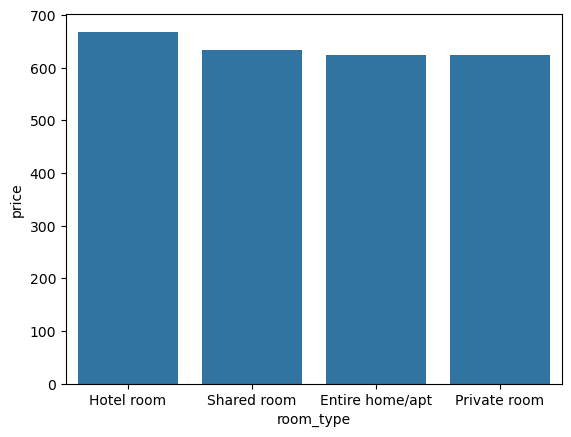

In [154]:
sb.barplot(ss)
plt.show()

In [155]:
corr = df[['price','number_of_reviews','minimum_nights','availability']].corr()
corr

,price,number_of_reviews,minimum_nights,availability
price,1.000000,0.005220,-0.003461,-0.002823
number_of_reviews,0.005220,1.000000,-0.049784,0.098712
minimum_nights,-0.003461,-0.049784,1.000000,0.059264
availability,-0.002823,0.098712,0.059264,1.000000


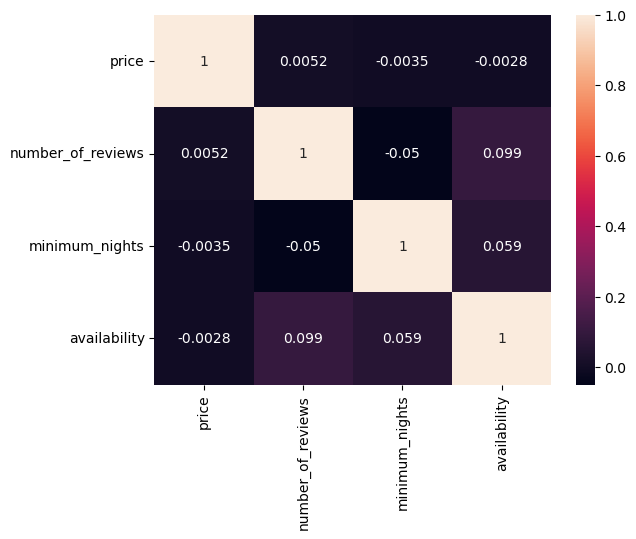

In [156]:
sb.heatmap(corr,annot=True)
plt.show()

In [157]:
df.last_review = df.last_review.astype('datetime64[ns]')

In [158]:
df.dtypes

name                                      object
host_id                                    int64
host_identity_verified                    object
host_name                                 object
neighbourhood_group                       object
neighbourhood                             object
country                                   object
instant_bookable                          object
cancellation_policy                       object
room_type                                 object
Construction_year                          int64
price                                      int64
service_fee                              float64
minimum_nights                           float64
number_of_reviews                        float64
last_review                       datetime64[ns]
reviews_per_month                        float64
review_rate_number                       float64
calculated_host_listings_count           float64
availability                             float64
house_rules         

In [159]:
#3. Availabiliy Trends

In [160]:
df['last_review'] = pd.to_datetime(df['last_review'], errors='coerce')
df['Year'] = df['last_review'].dt.year
df.groupby('Year')['availability'].describe()

,count,mean,std,min,25%,50%,75%,max
Year,,,,,,,,
1970,102599.0,141.133254,135.139008,-10.0,3.0,98.0,268.0,3677.0


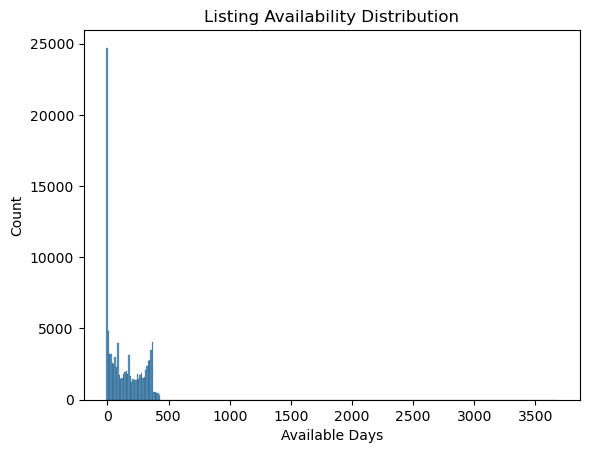

In [161]:
sb.histplot(df['availability'])
plt.title("Listing Availability Distribution")
plt.xlabel("Available Days")
plt.show()

In [162]:
df

,name,host_id,host_identity_verified,host_name,neighbourhood_group,neighbourhood,country,instant_bookable,cancellation_policy,room_type,...,minimum_nights,number_of_reviews,last_review,reviews_per_month,review_rate_number,calculated_host_listings_count,availability,house_rules,license,Year
0,Clean & quiet apt home by the park,80014485718,unconfirmed,Madaline,Brooklyn,Kensington,United States,False,strict,Private room,...,10.0,9.0,1970-01-01,0.210000,4.0,6.0,286.0,Clean up and treat the home the way you'd like...,unkown,1970
1,Skylit Midtown Castle,52335172823,verified,Jenna,Manhattan,Midtown,United States,False,moderate,Entire home/apt,...,30.0,45.0,1970-01-01,0.380000,4.0,2.0,228.0,Pet friendly but please confirm with me if the...,unkown,1970
2,THE VILLAGE OF HARLEM....NEW YORK !,78829239556,unkown,Elise,Manhattan,Harlem,United States,True,flexible,Private room,...,3.0,0.0,1970-01-01,1.374022,5.0,1.0,352.0,"I encourage you to use my kitchen, cooking and...",unkown,1970
3,unkown,85098326012,unconfirmed,Garry,Brooklyn,Clinton Hill,United States,True,moderate,Entire home/apt,...,30.0,270.0,1970-01-01,4.640000,4.0,1.0,322.0,unkown,unkown,1970
4,Entire Apt: Spacious Studio/Loft by central park,92037596077,verified,Lyndon,Manhattan,East Harlem,United States,False,moderate,Entire home/apt,...,10.0,9.0,1970-01-01,0.100000,3.0,1.0,289.0,"Please no smoking in the house, porch or on th...",unkown,1970
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
102594,Spare room in Williamsburg,12312296767,verified,Krik,Brooklyn,Williamsburg,United States,False,flexible,Private room,...,1.0,0.0,1970-01-01,1.374022,3.0,1.0,227.0,No Smoking No Parties or Events of any kind Pl...,unkown,1970
102595,Best Location near Columbia U,77864383453,unconfirmed,Mifan,Manhattan,Morningside Heights,United States,True,moderate,Private room,...,1.0,1.0,1970-01-01,0.020000,2.0,2.0,395.0,House rules: Guests agree to the following ter...,unkown,1970
102596,"Comfy, bright room in Brooklyn",69050334417,unconfirmed,Megan,Brooklyn,Park Slope,United States,True,moderate,Private room,...,3.0,0.0,1970-01-01,1.374022,5.0,1.0,342.0,unkown,unkown,1970
102597,Big Studio-One Stop from Midtown,11160591270,unconfirmed,Christopher,Queens,Long Island City,United States,True,strict,Entire home/apt,...,2.0,5.0,1970-01-01,0.100000,3.0,1.0,386.0,unkown,unkown,1970


In [163]:
df['Year'] = df['last_review'].dt.year

In [164]:
df

,name,host_id,host_identity_verified,host_name,neighbourhood_group,neighbourhood,country,instant_bookable,cancellation_policy,room_type,...,minimum_nights,number_of_reviews,last_review,reviews_per_month,review_rate_number,calculated_host_listings_count,availability,house_rules,license,Year
0,Clean & quiet apt home by the park,80014485718,unconfirmed,Madaline,Brooklyn,Kensington,United States,False,strict,Private room,...,10.0,9.0,1970-01-01,0.210000,4.0,6.0,286.0,Clean up and treat the home the way you'd like...,unkown,1970
1,Skylit Midtown Castle,52335172823,verified,Jenna,Manhattan,Midtown,United States,False,moderate,Entire home/apt,...,30.0,45.0,1970-01-01,0.380000,4.0,2.0,228.0,Pet friendly but please confirm with me if the...,unkown,1970
2,THE VILLAGE OF HARLEM....NEW YORK !,78829239556,unkown,Elise,Manhattan,Harlem,United States,True,flexible,Private room,...,3.0,0.0,1970-01-01,1.374022,5.0,1.0,352.0,"I encourage you to use my kitchen, cooking and...",unkown,1970
3,unkown,85098326012,unconfirmed,Garry,Brooklyn,Clinton Hill,United States,True,moderate,Entire home/apt,...,30.0,270.0,1970-01-01,4.640000,4.0,1.0,322.0,unkown,unkown,1970
4,Entire Apt: Spacious Studio/Loft by central park,92037596077,verified,Lyndon,Manhattan,East Harlem,United States,False,moderate,Entire home/apt,...,10.0,9.0,1970-01-01,0.100000,3.0,1.0,289.0,"Please no smoking in the house, porch or on th...",unkown,1970
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
102594,Spare room in Williamsburg,12312296767,verified,Krik,Brooklyn,Williamsburg,United States,False,flexible,Private room,...,1.0,0.0,1970-01-01,1.374022,3.0,1.0,227.0,No Smoking No Parties or Events of any kind Pl...,unkown,1970
102595,Best Location near Columbia U,77864383453,unconfirmed,Mifan,Manhattan,Morningside Heights,United States,True,moderate,Private room,...,1.0,1.0,1970-01-01,0.020000,2.0,2.0,395.0,House rules: Guests agree to the following ter...,unkown,1970
102596,"Comfy, bright room in Brooklyn",69050334417,unconfirmed,Megan,Brooklyn,Park Slope,United States,True,moderate,Private room,...,3.0,0.0,1970-01-01,1.374022,5.0,1.0,342.0,unkown,unkown,1970
102597,Big Studio-One Stop from Midtown,11160591270,unconfirmed,Christopher,Queens,Long Island City,United States,True,strict,Entire home/apt,...,2.0,5.0,1970-01-01,0.100000,3.0,1.0,386.0,unkown,unkown,1970


In [165]:
yn=df.groupby('Year')['name'].count().nsmallest(10)

In [166]:
yn

Year
1970    102599
Name: name, dtype: int64

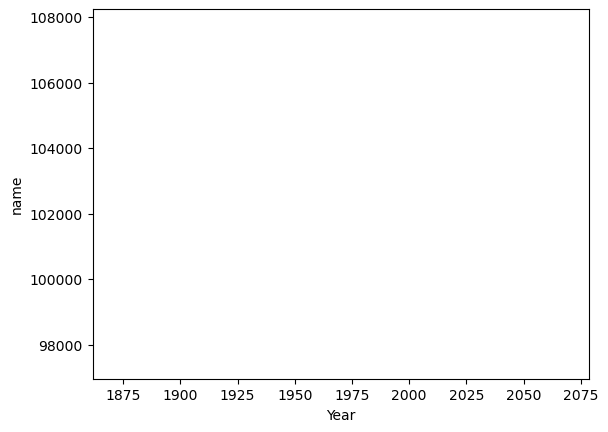

In [167]:
sb.lineplot(yn)
plt.show()

In [168]:
year=df.groupby('Year')['name'].count().nlargest(10)

In [169]:
year

Year
1970    102599
Name: name, dtype: int64

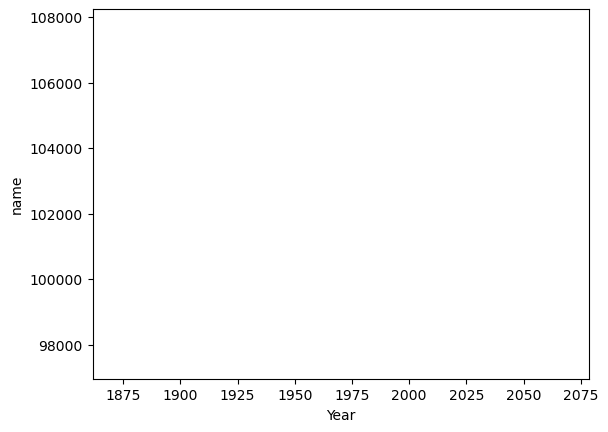

In [170]:
sb.lineplot(year)
plt.show()

In [171]:
df['Month'] = df['last_review'].dt.month

In [172]:
df

,name,host_id,host_identity_verified,host_name,neighbourhood_group,neighbourhood,country,instant_bookable,cancellation_policy,room_type,...,number_of_reviews,last_review,reviews_per_month,review_rate_number,calculated_host_listings_count,availability,house_rules,license,Year,Month
0,Clean & quiet apt home by the park,80014485718,unconfirmed,Madaline,Brooklyn,Kensington,United States,False,strict,Private room,...,9.0,1970-01-01,0.210000,4.0,6.0,286.0,Clean up and treat the home the way you'd like...,unkown,1970,1
1,Skylit Midtown Castle,52335172823,verified,Jenna,Manhattan,Midtown,United States,False,moderate,Entire home/apt,...,45.0,1970-01-01,0.380000,4.0,2.0,228.0,Pet friendly but please confirm with me if the...,unkown,1970,1
2,THE VILLAGE OF HARLEM....NEW YORK !,78829239556,unkown,Elise,Manhattan,Harlem,United States,True,flexible,Private room,...,0.0,1970-01-01,1.374022,5.0,1.0,352.0,"I encourage you to use my kitchen, cooking and...",unkown,1970,1
3,unkown,85098326012,unconfirmed,Garry,Brooklyn,Clinton Hill,United States,True,moderate,Entire home/apt,...,270.0,1970-01-01,4.640000,4.0,1.0,322.0,unkown,unkown,1970,1
4,Entire Apt: Spacious Studio/Loft by central park,92037596077,verified,Lyndon,Manhattan,East Harlem,United States,False,moderate,Entire home/apt,...,9.0,1970-01-01,0.100000,3.0,1.0,289.0,"Please no smoking in the house, porch or on th...",unkown,1970,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
102594,Spare room in Williamsburg,12312296767,verified,Krik,Brooklyn,Williamsburg,United States,False,flexible,Private room,...,0.0,1970-01-01,1.374022,3.0,1.0,227.0,No Smoking No Parties or Events of any kind Pl...,unkown,1970,1
102595,Best Location near Columbia U,77864383453,unconfirmed,Mifan,Manhattan,Morningside Heights,United States,True,moderate,Private room,...,1.0,1970-01-01,0.020000,2.0,2.0,395.0,House rules: Guests agree to the following ter...,unkown,1970,1
102596,"Comfy, bright room in Brooklyn",69050334417,unconfirmed,Megan,Brooklyn,Park Slope,United States,True,moderate,Private room,...,0.0,1970-01-01,1.374022,5.0,1.0,342.0,unkown,unkown,1970,1
102597,Big Studio-One Stop from Midtown,11160591270,unconfirmed,Christopher,Queens,Long Island City,United States,True,strict,Entire home/apt,...,5.0,1970-01-01,0.100000,3.0,1.0,386.0,unkown,unkown,1970,1


In [173]:
ma = df.groupby('Month')['availability'].mean()

In [174]:
ma

Month
1    141.133254
Name: availability, dtype: float64

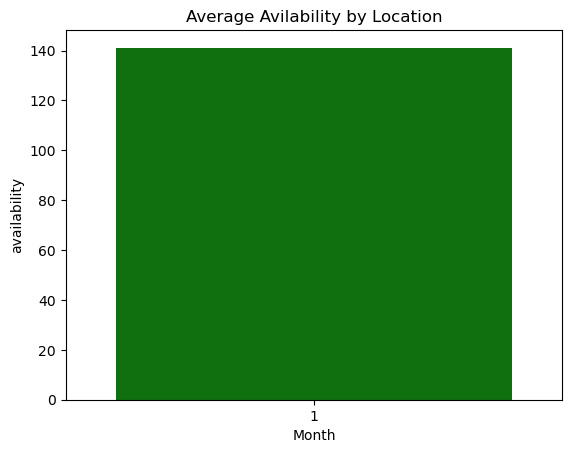

In [175]:
sb.barplot(ma,color='green')
plt.title("Average Avilability by Location")
plt.show()

In [176]:
# 4.Host Analysis

In [177]:
df.host_name.value_counts().nlargest(10)

host_name
Michael         881
David           764
John            581
Alex            546
Sonder (NYC)    516
Daniel          473
Karen           439
Sarah           434
Maria           426
unkown          406
Name: count, dtype: int64

In [178]:
df.groupby('host_identity_verified')['review_rate_number'].mean()

host_identity_verified
unconfirmed    3.271792
unkown         3.238434
verified       3.286663
Name: review_rate_number, dtype: float64

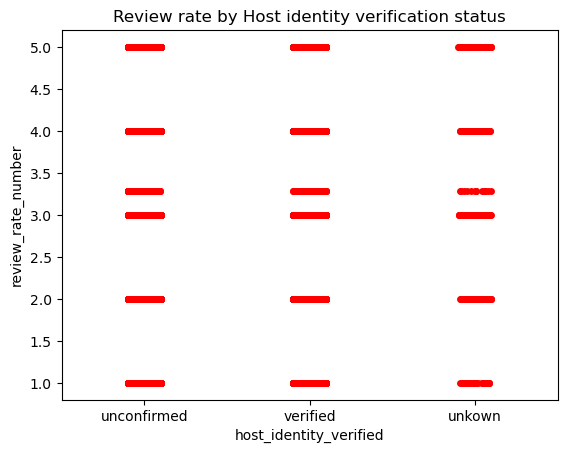

In [179]:
sb.stripplot(x=df.host_identity_verified,y=df.review_rate_number,color='red')
plt.title("Review rate by Host identity verification status")
plt.show()

In [180]:
df.groupby('host_name')['price'].mean().nlargest(10)

host_name
Antonin        1200.0
Chun Kit       1200.0
Denae          1200.0
Esaie          1200.0
Ilean          1200.0
Jeff & TJ      1200.0
Rema           1200.0
Alejandrina    1199.0
Gat            1199.0
J And Lana     1199.0
Name: price, dtype: float64

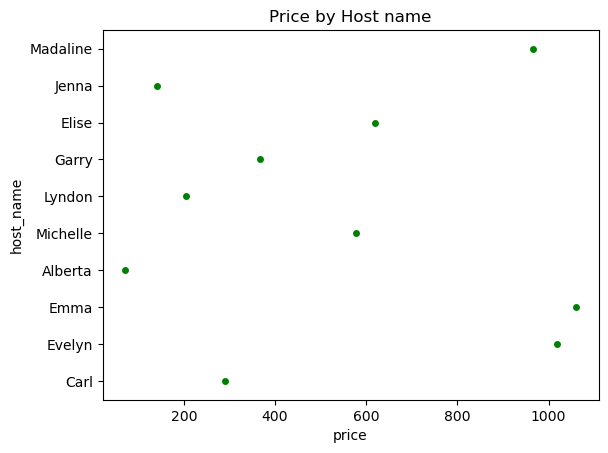

In [181]:
sb.stripplot(x=df.price[:10],y=df.host_name[:10],color='green')
plt.title("Price by Host name")
plt.show()

In [182]:
df.groupby('host_name')['number_of_reviews'].sum().nlargest(10)

host_name
Michael     24749.000000
David       17843.967486
John        15591.000000
Alex        13929.483743
Eric        12198.000000
Chris       12053.000000
Michelle    12005.000000
Anna        11613.000000
Kevin       11533.000000
Daniel      11206.483743
Name: number_of_reviews, dtype: float64

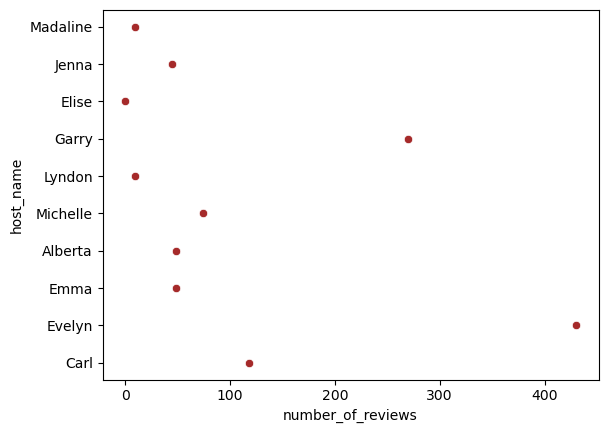

In [183]:
sb.scatterplot(x=df.number_of_reviews,y=df.host_name[:10],color='brown')
plt.show()

In [184]:
r = df.groupby('room_type')['number_of_reviews'].mean()

In [185]:
r

room_type
Entire home/apt    27.376032
Hotel room         83.439655
Private room       27.808172
Shared room        20.380952
Name: number_of_reviews, dtype: float64

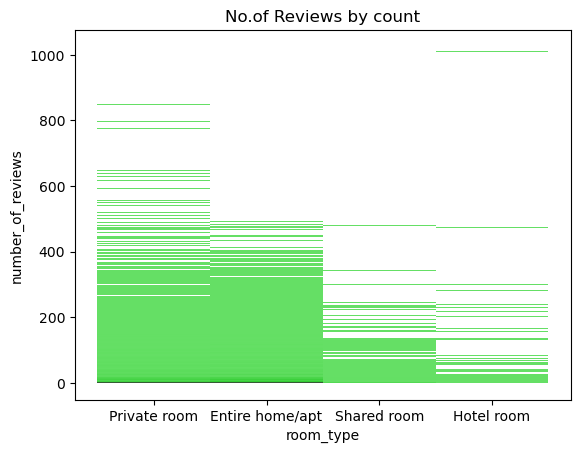

In [186]:
sb.histplot(x=df.room_type,y=df.number_of_reviews,color='green')
plt.title("No.of Reviews by count")
plt.show()

In [187]:
# 5.Customer Preferences

In [188]:
df.room_type.value_counts()

room_type
Entire home/apt    53701
Private room       46556
Shared room         2226
Hotel room           116
Name: count, dtype: int64

In [189]:
df.groupby('neighbourhood')['number_of_reviews'].sum().nlargest(10)

neighbourhood
Bedford-Stuyvesant    273183.288656
Williamsburg          192251.223627
Harlem                180120.321171
Bushwick              124094.288656
Hell's Kitchen        111861.451228
East Village           97879.934971
Crown Heights          89802.483743
East Harlem            83579.772399
Upper West Side        77909.902457
Upper East Side        70574.418714
Name: number_of_reviews, dtype: float64

In [190]:
df.groupby('minimum_nights')['number_of_reviews'].mean().nlargest(10)

minimum_nights
 149.0    294.0
 399.0    248.0
 119.0    233.0
 323.0    219.0
 350.0    206.0
-12.0     203.0
 131.0    166.0
 198.0    163.0
 273.0    150.0
-125.0    146.0
Name: number_of_reviews, dtype: float64

In [191]:
df.groupby('availability')['number_of_reviews'].mean().nlargest(10)

availability
 3677.0    232.000000
 366.0      57.545455
-6.0        57.000000
 202.0      55.476744
 232.0      53.835938
 240.0      53.155963
 253.0      52.776978
-10.0       52.648649
 60.0       50.925000
 228.0      50.716667
Name: number_of_reviews, dtype: float64

In [192]:
# 6.Anomaly Detection and Outliers

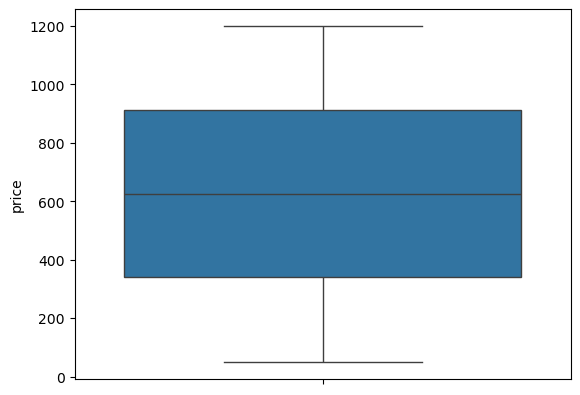

In [193]:
sb.boxplot(df.price)
plt.show()

In [194]:
df.groupby('neighbourhood')['price'].mean().nlargest(10)

neighbourhood
New Dorp                  1045.000000
Chelsea, Staten Island    1042.000000
Fort Wadsworth            1024.000000
Little Neck                817.750000
Jamaica Hills              812.904762
Arden Heights              804.888889
Midland Beach              796.176471
Shore Acres                792.260870
Mill Basin                 775.142857
Riverdale                  768.736842
Name: price, dtype: float64

In [195]:
df.groupby('neighbourhood')['availability'].mean().nlargest(10)

neighbourhood
Fort Wadsworth    365.000000
Glen Oaks         363.000000
Willowbrook       353.000000
West Brighton     272.830508
Co-op City        271.200000
Eastchester       271.004595
Midland Beach     267.882353
Concord           267.524590
West Farms        266.166667
Edgemere          265.500000
Name: availability, dtype: float64

In [196]:
# 7.Reviews and Rating Analysis

In [197]:
df.groupby('neighbourhood')['number_of_reviews'].mean()

neighbourhood
Allerton         56.618557
Arden Heights    15.555556
Arrochar         25.346154
Arverne          34.098655
Astoria          26.817663
                   ...    
Woodhaven        38.468750
Woodlawn         50.275862
Woodrow           7.000000
Woodside         21.742209
unkown           38.250000
Name: number_of_reviews, Length: 225, dtype: float64

In [198]:
df.groupby('neighbourhood')['review_rate_number'].mean()


neighbourhood
Allerton         3.281228
Arden Heights    3.777778
Arrochar         3.447675
Arverne          3.228700
Astoria          3.230488
                   ...   
Woodhaven        3.328125
Woodlawn         3.310345
Woodrow          4.000000
Woodside         3.409113
unkown           3.437500
Name: review_rate_number, Length: 225, dtype: float64

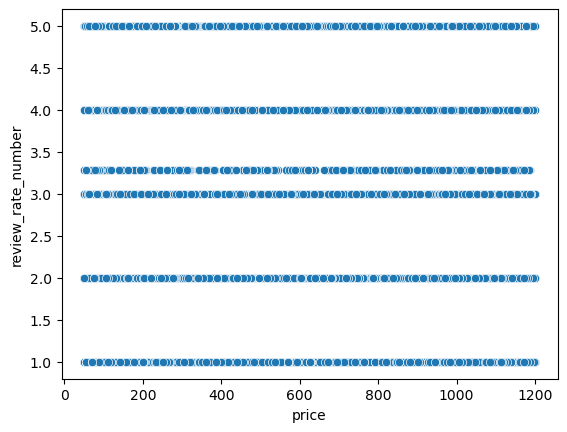

In [199]:
sb.scatterplot(x='price',y='review_rate_number',data=df)
plt.show()

In [200]:
df.groupby('host_name')['review_rate_number'].mean().nlargest(10)

host_name
5 Star Stays    5.0
A.G.            5.0
AGood           5.0
Aamir           5.0
Abbi            5.0
Abdul Rahman    5.0
Abhinaya        5.0
Abimbola        5.0
Abinav          5.0
Abosede         5.0
Name: review_rate_number, dtype: float64

In [201]:
rating = df.groupby('name')['review_rate_number'].mean()

In [202]:
rating.tail(10)

name
😍L@@K!😍 Sunlit 3 bedroom in 20ft wide brownstone      5.0
😎Bedstuy is fly 😎                                     5.0
😸Cirilo's G. Nice Private Room🪴🐈‍⬛                    3.0
🛫Room Private LGA👩🏻‍✈️                                2.0
🥰Elegant large studio/central/Wifi/nearTimesSquare    4.0
🥰Lovely 1 bedroom/5 minutes walk to timessquare       2.0
🧑🏼‍✈️Private Room LGA ✈️                              5.0
🪁LARGE PRIVATE TERRACE 🚶‍♂️8 MIN WALK TO MAIN ST      3.0
🪴XL dojo 🌾 shared green yogi palace apt 🌿             4.0
🪴🛋🌞 Unique sunny clean brownstone studio 1st floor    5.0
Name: review_rate_number, dtype: float64

C:\Users\yawal\AppData\Local\Temp\ipykernel_14816\2648656310.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sb.barplot(x=rating.head(10).values,y=rating.head(10).index,palette='plasma')


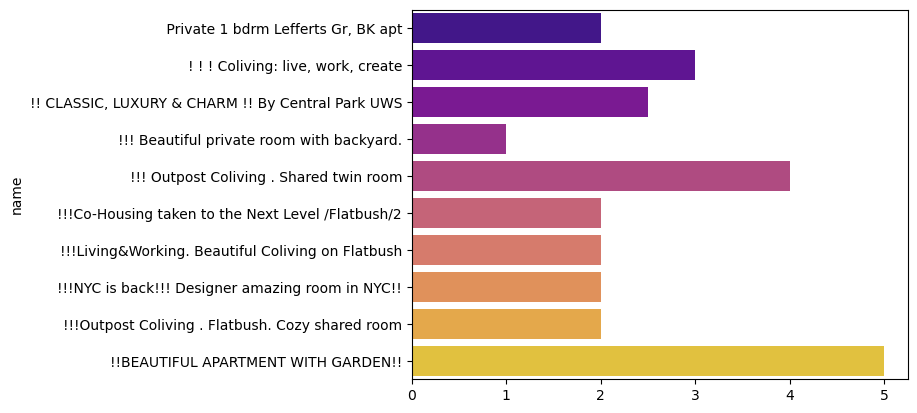

In [203]:
sb.barplot(x=rating.head(10).values,y=rating.head(10).index,palette='plasma')
plt.show()

In [204]:
# Dashboard:

In [205]:
#1.Total Listing overall

print('Total Listening:',df.host_id.count())
print('Average Price:',df.price.mean())
print('Average Availability:',df.availability.mean())
print('Total Host:',df.host_id.nunique())
print('Total Reviews:',df.number_of_reviews.sum())

Total Listening: 102599
Average Price: 625.2928293648087
Average Availability: 141.1332537126411
Total Host: 102057
Total Reviews: 2819804.5249277456


In [206]:
# Visualization

C:\Users\yawal\AppData\Local\Temp\ipykernel_14816\4043040769.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sb.barplot(n_l,palette='pastel')
C:\Users\yawal\AppData\Local\Temp\ipykernel_14816\4043040769.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sb.barplot(n_p,palette='plasma')
C:\Users\yawal\AppData\Local\Temp\ipykernel_14816\4043040769.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sb.barplot(p,palette='Greens')
C:\Users\yawal\AppData\Local\Temp\ipykernel_14816\4043040769.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and 

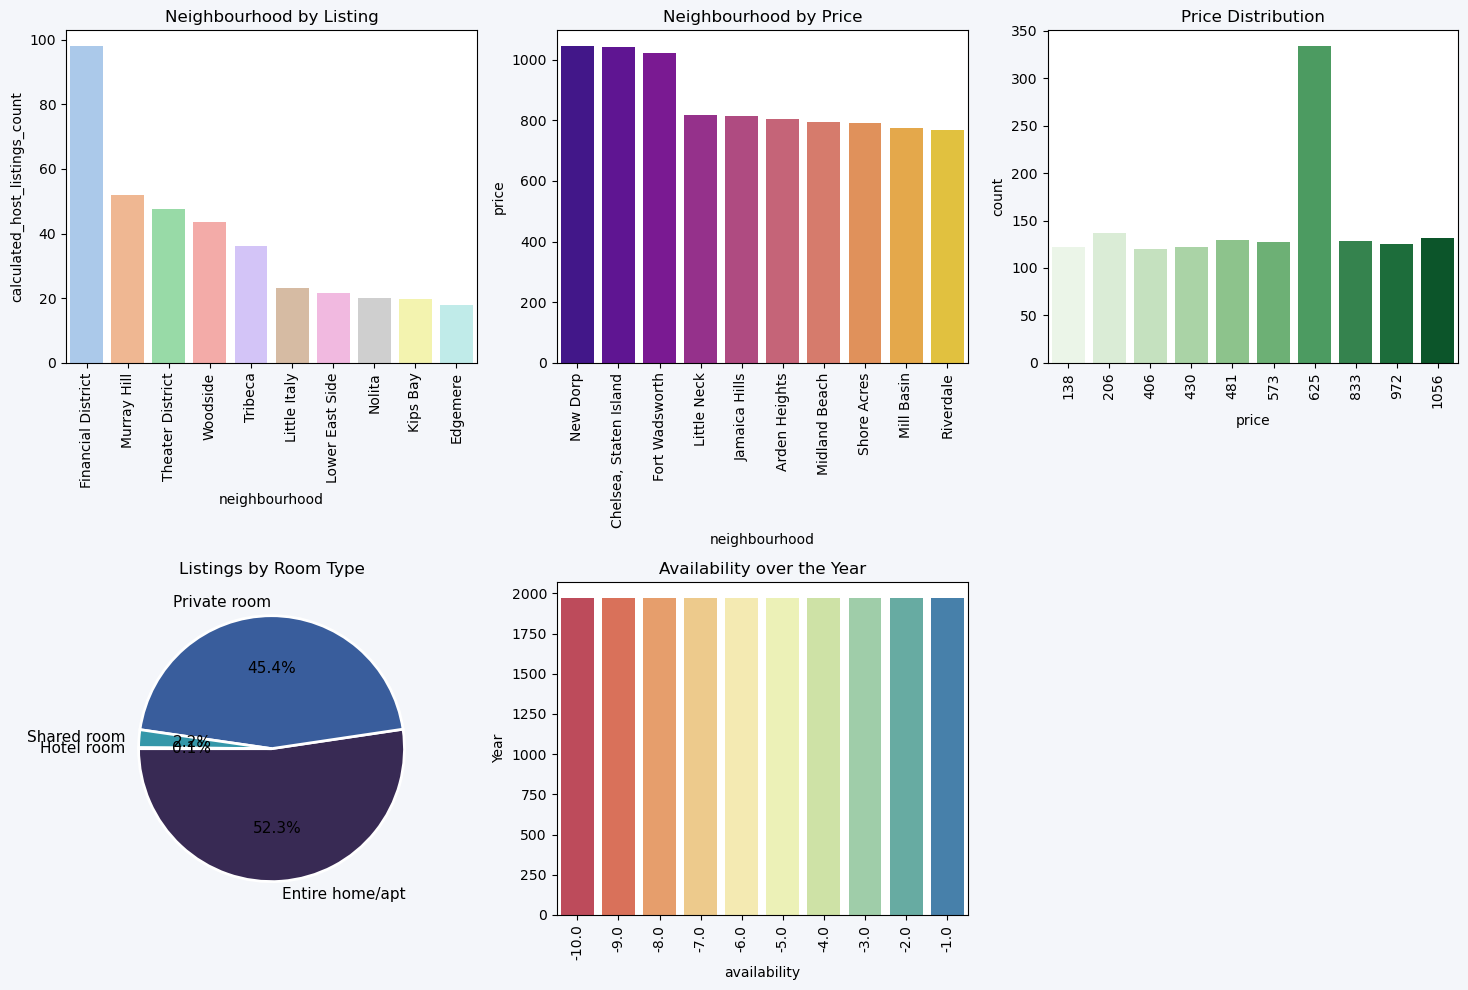

In [209]:
plt.figure(figsize=(15,10),facecolor="#F4F6FA")

plt.subplot(2,3,1)

n_l = df.groupby('neighbourhood')['calculated_host_listings_count'].mean().nlargest(10)
plt.title("Neighbourhood by Listing")
plt.xticks(rotation=90)
sb.barplot(n_l,palette='pastel')

plt.subplot(2,3,2)
n_p = df.groupby('neighbourhood')['price'].mean().nlargest(10)
plt.title("Neighbourhood by Price")
plt.xticks(rotation=90)
sb.barplot(n_p,palette='plasma')

plt.subplot(2,3,3)
p = df.price.value_counts().nlargest(10)
plt.title("Price Distribution")
plt.xticks(rotation=90)
sb.barplot(p,palette='Greens')

plt.subplot(2, 3, 4)
r_t = df.room_type.value_counts().nlargest(10)
plt.pie(r_t.values,labels=r_t.index,autopct='%1.1f%%',colors=sb.color_palette('mako', len(r_t)),
        startangle=180,labeldistance=1.1,textprops={'color': 'Black', 'fontsize': 11},
        wedgeprops={'linewidth':2, 'edgecolor':'white'})
plt.title("Listings by Room Type")


plt.subplot(2,3,5)
a_y = df.groupby('availability')['Year'].mean().nlargest(10)
plt.title("Availability over the Year")
plt.xticks(rotation=90)
sb.barplot(a_y,palette='Spectral')

plt.tight_layout()
plt.show()